In [ ]:
!pip install -q transformers sentencepiece spacy pandas numpy matplotlib seaborn scikit-learn plotly
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import spacy
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
import os

print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'dataset_lab3.zip', 'sample_data']


In [ ]:
zip_path = "/content/dataset_lab3.zip"
extract_path = "/content/dataset_lab3"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
print(os.listdir(extract_path))

['restaurants-trial.csv', 'Restaurants_Test_Data_PhaseA.xml', 'Laptops_Test_Data_PhaseB.csv', 'Laptop_Train_v2.xml', 'restaurants-trial.xml', 'Laptops_Test_Data_PhaseA.csv', 'laptops-trial.xml', 'Restaurants_Train.xml', 'SemEvalSchema.xsd', 'Laptops_Test_Data_PhaseA.xml', 'Restaurants_Train_v2.xml', 'Restaurants_Test_Data_phaseB.xml', 'Laptop_Train_v2.csv', 'Restaurants_Train_v2.csv', 'Restaurants_Test_Data_PhaseB.csv', 'Restaurants_Test_Data_PhaseA.csv', 'Laptops_Test_Data_phaseB.xml', 'laptops-trial.csv']


In [ ]:
train_path = "/content/dataset_lab3/Laptop_Train_v2.csv"

train_df = pd.read_csv(train_path)

print("Training dataset loaded!")
print("Shape:", train_df.shape)

train_df.head()

Training dataset loaded!
Shape: (2358, 6)


,id,Sentence,Aspect Term,polarity,from,to
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86
2,1316,The tech guy then said the service center does...,service center,negative,27,41
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12


In [ ]:
print("Columns:")
print(train_df.columns.tolist())

print("\nDataset information:")
print(train_df.info())

print("\nMissing values:")
print(train_df.isnull().sum())

Columns:
['id', 'Sentence', 'Aspect Term', 'polarity', 'from', 'to']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2358 entries, 0 to 2357
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           2358 non-null   int64 
 1   Sentence     2358 non-null   object
 2   Aspect Term  2358 non-null   object
 3   polarity     2358 non-null   object
 4   from         2358 non-null   int64 
 5   to           2358 non-null   int64 
dtypes: int64(3), object(3)
memory usage: 110.7+ KB
None

Missing values:
id             0
Sentence       0
Aspect Term    0
polarity       0
from           0
to             0
dtype: int64


polarity
positive    987
negative    866
neutral     460
conflict     45
Name: count, dtype: int64


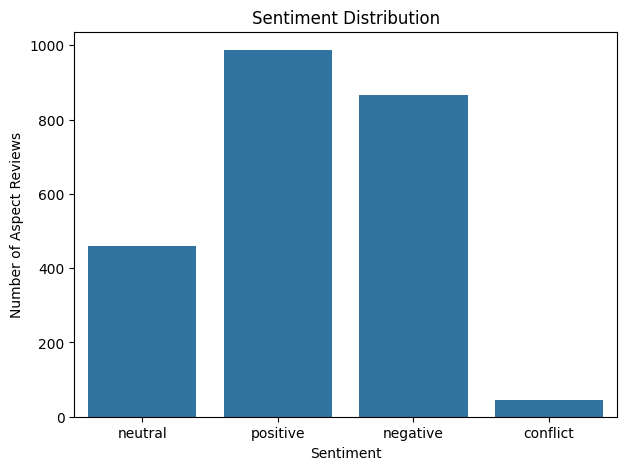

In [ ]:
print(train_df["polarity"].value_counts())
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="polarity"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Aspect Reviews")

plt.show()

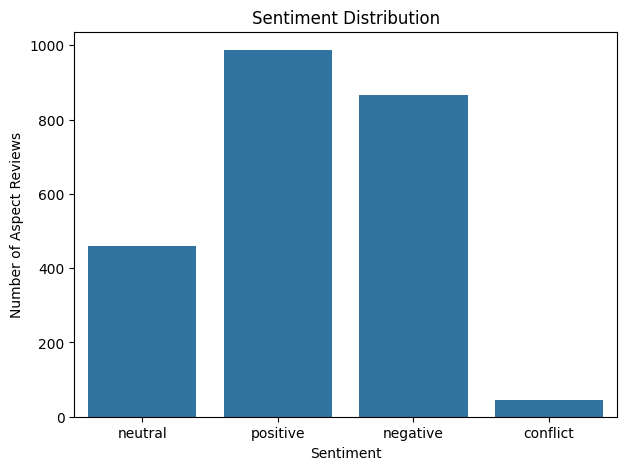

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="polarity"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Aspect Reviews")

plt.show()

In [ ]:
display(
    train_df[
        ["Sentence", "Aspect Term", "polarity"]
    ].head(15)
)

,Sentence,Aspect Term,polarity
0,I charge it at night and skip taking the cord ...,cord,neutral
1,I charge it at night and skip taking the cord ...,battery life,positive
2,The tech guy then said the service center does...,service center,negative
3,The tech guy then said the service center does...,"""sales"" team",negative
4,The tech guy then said the service center does...,tech guy,neutral
5,"it is of high quality, has a killer GUI, is ex...",quality,positive
6,"it is of high quality, has a killer GUI, is ex...",GUI,positive
7,"it is of high quality, has a killer GUI, is ex...",applications,positive
8,"it is of high quality, has a killer GUI, is ex...",use,positive
9,Easy to start up and does not overheat as much...,start up,positive


In [ ]:
model_name = "yangheng/deberta-v3-base-absa-v1.1"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Using device:", device)

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/18.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Model loaded successfully!
Using device: cpu


In [ ]:
print(model.config.id2label)

{0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:
def predict_aspect_sentiment(sentence, aspect):

    inputs = tokenizer(
        sentence,
        aspect,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=1
    )[0]

    predicted_id = torch.argmax(probabilities).item()

    label = model.config.id2label[predicted_id]

    confidence = probabilities[predicted_id].item()

    return label.lower(), confidence

In [ ]:
sentence = "The laptop has an amazing display but the battery life is disappointing."

aspect = "display"

sentiment, confidence = predict_aspect_sentiment(
    sentence,
    aspect
)

print("Sentence:", sentence)
print("Aspect:", aspect)
print("Predicted Sentiment:", sentiment)
print("Confidence:", round(confidence, 4))
sentence = "The laptop has an amazing display but the battery life is disappointing."

aspect = "battery life"

sentiment, confidence = predict_aspect_sentiment(
    sentence,
    aspect
)

print("Aspect:", aspect)
print("Predicted Sentiment:", sentiment)
print("Confidence:", round(confidence, 4))

Sentence: The laptop has an amazing display but the battery life is disappointing.
Aspect: display
Predicted Sentiment: positive
Confidence: 0.9977
Aspect: battery life
Predicted Sentiment: negative
Confidence: 0.9961


In [ ]:
sample_df = train_df.head(100).copy()

predictions = []
confidences = []

for _, row in sample_df.iterrows():

    sentiment, confidence = predict_aspect_sentiment(
        row["Sentence"],
        row["Aspect Term"]
    )

    predictions.append(sentiment)
    confidences.append(confidence)

sample_df["predicted_sentiment"] = predictions
sample_df["confidence"] = confidences

sample_df.head()

,id,Sentence,Aspect Term,polarity,from,to,predicted_sentiment,confidence
0,2339,I charge it at night and skip taking the cord ...,cord,neutral,41,45,neutral,0.983368
1,2339,I charge it at night and skip taking the cord ...,battery life,positive,74,86,positive,0.997770
2,1316,The tech guy then said the service center does...,service center,negative,27,41,negative,0.993933
3,1316,The tech guy then said the service center does...,"""sales"" team",negative,109,121,negative,0.995660
4,1316,The tech guy then said the service center does...,tech guy,neutral,4,12,negative,0.987393


In [ ]:
comparison_df = sample_df[
    [
        "Sentence",
        "Aspect Term",
        "polarity",
        "predicted_sentiment",
        "confidence"
    ]
]

display(comparison_df.head(20))

,Sentence,Aspect Term,polarity,predicted_sentiment,confidence
0,I charge it at night and skip taking the cord ...,cord,neutral,neutral,0.983368
1,I charge it at night and skip taking the cord ...,battery life,positive,positive,0.997770
2,The tech guy then said the service center does...,service center,negative,negative,0.993933
3,The tech guy then said the service center does...,"""sales"" team",negative,negative,0.995660
4,The tech guy then said the service center does...,tech guy,neutral,negative,0.987393
5,"it is of high quality, has a killer GUI, is ex...",quality,positive,positive,0.997703
6,"it is of high quality, has a killer GUI, is ex...",GUI,positive,positive,0.998111
7,"it is of high quality, has a killer GUI, is ex...",applications,positive,positive,0.994769
8,"it is of high quality, has a killer GUI, is ex...",use,positive,positive,0.997276
9,Easy to start up and does not overheat as much...,start up,positive,positive,0.997862


In [ ]:
accuracy = accuracy_score(
    sample_df["polarity"],
    sample_df["predicted_sentiment"]
)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 91.0 %


In [ ]:
precision, recall, f1, _ = precision_recall_fscore_support(
    sample_df["polarity"],
    sample_df["predicted_sentiment"],
    average="weighted",
    zero_division=0
)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Precision: 0.893
Recall: 0.91
F1 Score: 0.9011


In [ ]:
print(
    classification_report(
        sample_df["polarity"],
        sample_df["predicted_sentiment"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    conflict       0.00      0.00      0.00         2
    negative       0.93      0.97      0.95        39
     neutral       0.80      0.84      0.82        19
    positive       0.95      0.93      0.94        40

    accuracy                           0.91       100
   macro avg       0.67      0.69      0.68       100
weighted avg       0.89      0.91      0.90       100



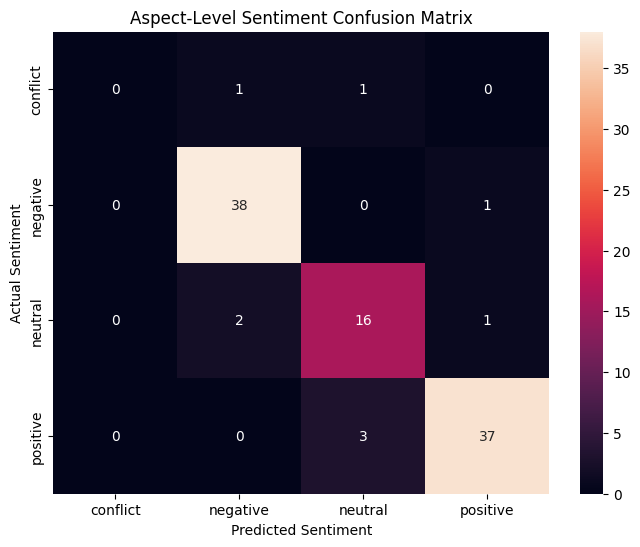

In [ ]:
labels = sorted(
    list(
        set(sample_df["polarity"]) |
        set(sample_df["predicted_sentiment"])
    )
)

cm = confusion_matrix(
    sample_df["polarity"],
    sample_df["predicted_sentiment"],
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Aspect-Level Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [ ]:
nlp = spacy.load("en_core_web_sm")

def extract_candidate_aspects(review):

    doc = nlp(review)

    aspects = []

    # Noun chunks
    for chunk in doc.noun_chunks:
        phrase = chunk.text.strip()

        if len(phrase) > 1:
            aspects.append(phrase)

    # Individual nouns and proper nouns
    for token in doc:

        if token.pos_ in ["NOUN", "PROPN"]:

            word = token.text.strip()

            if len(word) > 1:
                aspects.append(word)

    # Remove duplicates
    unique_aspects = []

    for aspect in aspects:

        if aspect.lower() not in [
            x.lower() for x in unique_aspects
        ]:
            unique_aspects.append(aspect)

    return unique_aspects

In [ ]:
review = """
The laptop has an amazing display and a very fast processor,
but the battery life is disappointing and the keyboard feels cheap.
"""

aspects = extract_candidate_aspects(review)

print("Candidate aspects:")

for aspect in aspects:
    print("-", aspect)

Candidate aspects:
- The laptop
- an amazing display
- a very fast processor
- the battery life
- the keyboard
- laptop
- display
- processor
- battery
- life
- keyboard


In [ ]:
def analyze_review(review):

    aspects = extract_candidate_aspects(review)

    results = []

    for aspect in aspects:

        sentiment, confidence = predict_aspect_sentiment(
            review,
            aspect
        )

        results.append({
            "Aspect": aspect,
            "Sentiment": sentiment,
            "Confidence": round(confidence, 4)
        })

    return pd.DataFrame(results)

In [ ]:
new_review = """
The laptop has an amazing display and a very fast processor,
but the battery life is disappointing and the keyboard feels cheap.
"""

result = analyze_review(new_review)

display(result)

,Aspect,Sentiment,Confidence
0,The laptop,positive,0.6091
1,an amazing display,positive,0.9907
2,a very fast processor,positive,0.9177
3,the battery life,negative,0.9964
4,the keyboard,negative,0.9958
5,laptop,neutral,0.6940
6,display,positive,0.9970
7,processor,positive,0.9962
8,battery,negative,0.9955
9,life,negative,0.9965


In [ ]:
positive_aspects = result[
    result["Sentiment"].str.contains("positive", case=False, na=False)
]

negative_aspects = result[
    result["Sentiment"].str.contains("negative", case=False, na=False)
]

print("Positive Aspects:")
display(positive_aspects)

print("Negative Aspects:")
display(negative_aspects)

Positive Aspects:


,Aspect,Sentiment,Confidence
0,The laptop,positive,0.6091
1,an amazing display,positive,0.9907
2,a very fast processor,positive,0.9177
6,display,positive,0.9970
7,processor,positive,0.9962


Negative Aspects:


,Aspect,Sentiment,Confidence
3,the battery life,negative,0.9964
4,the keyboard,negative,0.9958
8,battery,negative,0.9955
9,life,negative,0.9965
10,keyboard,negative,0.9959


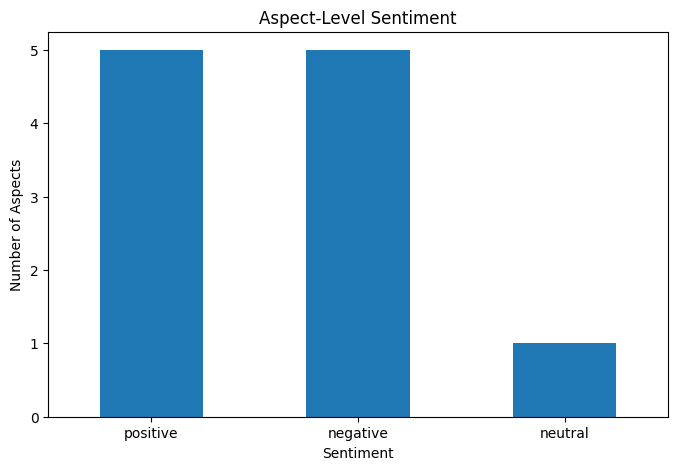

In [ ]:
sentiment_counts = result["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sentiment_counts.plot(
    kind="bar"
)

plt.title("Aspect-Level Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Aspects")

plt.xticks(rotation=0)

plt.show()

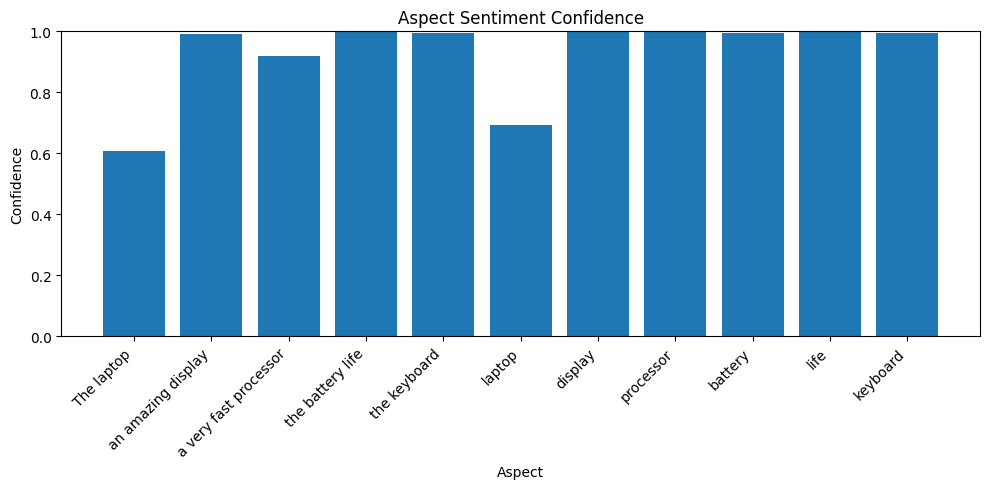

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    result["Aspect"],
    result["Confidence"]
)

plt.title("Aspect Sentiment Confidence")
plt.xlabel("Aspect")
plt.ylabel("Confidence")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 1)

plt.tight_layout()

plt.show()

In [ ]:
fig = px.bar(
    result,
    x="Aspect",
    y="Confidence",
    color="Sentiment",
    title="Product Review Intelligence Dashboard",
    text="Confidence"
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside"
)

fig.update_layout(
    xaxis_title="Product Aspect",
    yaxis_title="Confidence Score",
    yaxis_range=[0, 1]
)

fig.show()

In [ ]:
dashboard_df = result.copy()

dashboard_df["Aspect"] = dashboard_df["Aspect"].astype(str)

fig = px.bar(
    dashboard_df,
    x="Aspect",
    y="Confidence",
    color="Sentiment",
    title="Product Review Intelligence",
    hover_data=["Sentiment", "Confidence"],
    text="Sentiment"
)

fig.update_layout(
    xaxis_title="Product Aspect",
    yaxis_title="Confidence",
    yaxis_range=[0, 1]
)

fig.show()